# TP1 — Análisis descriptivo y predicción de informalidad

**Machine Learning para Economistas — UdeSA, 2026**  
**Profesor:** Walter Sosa Escudero  
**Grupo:** 8

El objetivo del trabajo es analizar las características socioeconómicas asociadas a la informalidad laboral en Argentina y evaluar distintos modelos de clasificación utilizando la Encuesta Permanente de Hogares (EPH) del primer trimestre de 2026.

---

# 0. Configuración y preparación de datos

## 0.1. Importación de librerías

Se importan las librerías necesarias para manipulación de datos, visualización y descarga de archivos.

In [17]:
import pandas as pd
import numpy as np

import os
from os.path import join
from pathlib import Path
from os import makedirs, remove

import seaborn as sns
import matplotlib.pyplot as plt

import requests
import zipfile

## 0.2. Definición de directorios

Se establece la estructura de carpetas del proyecto, diferenciando entre datos originales, resultados, programas y documentos LaTeX.

In [33]:
main_path = Path("D:/Github/PE1333_Grupo8/TP_01")

# Directorios principales
a_path = join(main_path, "A_Inputs")
b_path = join(main_path, "B_Outputs")
c_path = join(main_path, "C_Programs")
d_path = join(main_path, "D_LaTeX")

# Subdirectorios de resultados
b_path_data = join(b_path, "B_Data")
b_path_figr = join(b_path, "B_Figure")
b_path_tabl = join(b_path, "B_Table")
b_path_text = join(b_path, "B_Text")

## 0.3. Descarga e importación de datos

Se utilizan las bases de microdatos individuales y de hogares de la Encuesta Permanente de Hogares (EPH) correspondientes al primer trimestre de 2026, publicadas por el Instituto Nacional de Estadística y Censos (INDEC).

Para asegurar la reproducibilidad, se automatiza la descarga de los archivos originales desde la página del INDEC.

In [19]:
# ============================================================
# 0.3. DESCARGA DE DATOS
# ============================================================

for year in [2026]:
    for trim in range(1, 2):

        url = (
            "https://www.indec.gob.ar/ftp/cuadros/menusuperior/eph/"
            f"EPH_usu_{trim}_Trim_{year}_txt.zip"
        )

        destino = a_path
        makedirs(destino, exist_ok=True)

        archivo_indiv = join(destino, f"usu_individual_T{trim}{str(year)[-2:]}.txt")
        archivo_hogar = join(destino, f"usu_hogar_T{trim}{str(year)[-2:]}.txt")

        if os.path.exists(archivo_indiv) and os.path.exists(archivo_hogar):
            print(f"Archivos existentes: {year}-T{trim}")
            continue

        response = requests.get(url, timeout=120)
        response.raise_for_status()

        archivo_zip = join(destino, "EPH.zip")

        with open(archivo_zip, "wb") as f:
            f.write(response.content)

        try:
            with zipfile.ZipFile(archivo_zip, "r") as z:
                z.extractall(destino)

            print(f"Descargado: {year}-T{trim}")

        finally:
            if os.path.exists(archivo_zip):
                remove(archivo_zip)

# ============================================================
# 0.4. IMPORTACIÓN DE BASES
# ============================================================
datos_indiv_raw = pd.read_csv(join(a_path, "usu_individual_T126.txt"), sep=";", encoding="utf-8", low_memory=False)
datos_hogar_raw = pd.read_csv(join(a_path, "usu_hogar_T126.txt"), sep=";", encoding="utf-8", low_memory=False)

Archivos existentes: 2026-T1


# Parte I. Analizando la base

## 1. Consigna 1 — Selección y limpieza de variables

Se restringe la muestra a los individuos ocupados (`ESTADO = 1`) y se construye la variable dependiente `informal` a partir de `EMPLEO`:

- `informal = 0`: trabajador formal.
- `informal = 1`: trabajador informal.

Se excluyen las observaciones con `EMPLEO = 9`, correspondientes a personas sin clasificación válida de formalidad.

In [20]:
# ============================================================
# 1.1. SELECCIÓN DE OCUPADOS Y VARIABLE DEPENDIENTE
# ============================================================

# Conservar ocupados con clasificación válida
datos_indiv = datos_indiv_raw.loc[
    (datos_indiv_raw["ESTADO"] == 1) &
    (datos_indiv_raw["EMPLEO"].isin([1, 2]))
].copy()

# Variable dependiente: 1 = informal, 0 = formal
datos_indiv["informal"] = (
    datos_indiv["EMPLEO"].map({1: 0, 2: 1}).astype(int)
)

print("Observaciones:", len(datos_indiv))
print(datos_indiv["informal"].value_counts())

Observaciones: 19560
informal
0    10762
1     8798
Name: count, dtype: int64



### 1.2. Selección de variables socioeconómicas

Se seleccionan 15 variables explicativas agrupadas en cuatro dimensiones:

- **Características demográficas:** parentesco, sexo, edad, estado conyugal y movilidad geográfica.
- **Capital humano:** alfabetización, asistencia educativa y nivel educativo.
- **Características laborales:** categoría ocupacional, deseo de trabajar más horas, intensidad laboral y sector de gestión.
- **Características geográficas:** región y tamaño del aglomerado.

Estas dimensiones permiten incorporar información sobre características individuales, acumulación de capital humano y heterogeneidad de los mercados laborales.


In [ ]:

# ============================================================
# 1.2. SELECCIÓN DE VARIABLES SOCIOECONÓMICAS
# ============================================================

# Características demográficas
variables_demograficas = [
    "CH03",      # Parentesco
    "CH04",      # Sexo
    "CH06",      # Edad
    "CH07",      # Estado conyugal
    "CH15",      # Lugar de nacimiento
    "CH16"       # Residencia hace 5 años
]

# Capital humano
variables_educacion = [
    "CH09",      # Alfabetización
    "CH10",      # Asistencia educativa
    "NIVEL_ED"   # Nivel educativo
]

# Características laborales
variables_laborales = [
    "CAT_OCUP",  # Categoría ocupacional
    "PP03G",     # Deseo de trabajar más horas
    "INTENSI",   # Intensidad laboral
    "PP04A"      # Sector de gestión
]

# Características geográficas
variables_geograficas = [
    "REGION",    # Región
    "MAS_500"    # Tamaño del aglomerado
]

# Lista completa de predictoras
variables_x = (
    variables_demograficas
    + variables_educacion
    + variables_laborales
    + variables_geograficas
)

print("Número de predictoras:", len(variables_x))

Número de predictoras: 15



### 1.3. Exploración de valores y códigos de no respuesta

Se examinan los valores únicos de las 15 variables seleccionadas para identificar posibles códigos especiales, valores inválidos o respuestas faltantes.

La identificación de estos códigos se realiza considerando el Diseño de Registro de la EPH del INDEC, dado que un mismo código numérico puede representar categorías diferentes según la variable.


In [27]:
for var in variables_x:
    print(f"{var}: {datos_indiv[var].unique()}")

CH03: [ 2  1  3  8  9  5  4  6 10  7]
CH04: [2 1]
CH06: [44 56 52 48 26 25 49 53 20 30 61 58 69 71 36 43 38 74 27 45 21 50 35 46
 39 37 60 51 40 54 22 29 41 47 32 31 66 70 55 62 76 34 64 65 33 18 59 42
 28 19 63 24 16 23 67 75 57 17 79 68 72 73 84 80 77 81 15 78 83 82 12 86
 14 99 13 85 88 10 87]
CH07: [2 5 3 1 4]
CH15: [ 2.  1.  3.  4.  5. nan]
CH16: [ 1.  2.  3.  4.  5. nan]
CH09: [ 1.  2. nan]
CH10: [2 1 3]
NIVEL_ED: [6 5 4 2 3 1 7]
CAT_OCUP: [3 2 1 4]
PP03G: [ 2.  1. nan]
INTENSI: [2. 1. 3. 4.]
PP04A: [1. 2. 3.]
REGION: [44 40 43 41  1 42]
MAS_500: <StringArray>
['N', 'S']
Length: 2, dtype: str



### 1.4. Limpieza de valores sin sentido

De acuerdo con los códigos de la EPH, se identifican valores `9` correspondientes a respuestas no informadas (`Ns/Nr`) en las variables `CH15`, `CH16`, `CH09` y `PP03G`.

Estos códigos se reemplazan por valores faltantes (`NaN`), evitando interpretarlos como categorías socioeconómicas válidas. No se eliminan observaciones en esta etapa.

Los valores faltantes serán analizados en la consigna 3.


In [28]:
# Variables con código 9 = Ns/Nr
variables_ns_nr = ["CH15", "CH16", "CH09", "PP03G"]

# Reemplazar 9 por NaN
datos_indiv[variables_ns_nr] = (datos_indiv[variables_ns_nr].replace(9, np.nan))

# Verificar valores faltantes
print(datos_indiv[variables_x].isna().sum().sort_values(ascending=False))

PP03G       6
CH15        2
CH16        1
CH09        1
CH06        0
CH03        0
CH04        0
CH07        0
CH10        0
NIVEL_ED    0
CAT_OCUP    0
INTENSI     0
PP04A       0
REGION      0
MAS_500     0
dtype: int64


### 1.5. Exclusión de variables que definen la informalidad

Se excluyen de la matriz de predictores las variables utilizadas directamente para construir `EMPLEO`, incluyendo información sobre descuentos jubilatorios, aportes, beneficios y registros laborales.

Su inclusión produciría *data leakage*, ya que el modelo utilizaría información contenida en la propia definición de la variable dependiente. Esto podría generar un ajuste artificialmente elevado que no necesariamente se sostendría en aplicaciones donde dicha información no estuviera disponible.

In [25]:
# ============================================================
# 1.5. VERIFICACIÓN DE VARIABLES EXCLUIDAS
# ============================================================

variables_prohibidas = [
    "EMPLEO", "SECTOR",
    "PP07H", "PP07I",
    "PP07G1", "PP07G2", "PP07G3", "PP07G4",
    "PP07G_59", "PP07K", "PP07L",
    "PP05I", "PP05J", "PP05K"
]

# Comprobar que ninguna variable prohibida aparece en X
assert not set(variables_x).intersection(variables_prohibidas)

print("Selección de predictores validada.")

Selección de predictores validada.


## 2. Consigna 2 — Construcción de nuevas variables

Se construyen al menos tres variables adicionales que
permitan incorporar información socioeconómica relevante
para la predicción de la informalidad laboral.

In [31]:

# ============================================================
# 2.2. HORAS TOTALES TRABAJADAS
# ============================================================

# Variables de horas trabajadas
variables_horas = ["PP3E_TOT", "PP3F_TOT"]

# Identificar códigos inválidos
for var in variables_horas:
    print(f"{var}: {(datos_indiv[var] == 999).sum()} casos con 999")

# Reemplazar valores inválidos por NaN
datos_indiv[variables_horas] = (
    datos_indiv[variables_horas].replace(999, np.nan)
)

# Construir horas totales trabajadas
datos_indiv["horastrab"] = (
    datos_indiv["PP3E_TOT"] + datos_indiv["PP3F_TOT"]
)

# Estadísticas descriptivas
display(datos_indiv["horastrab"].describe())

# Verificar valores faltantes
print("Faltantes:", datos_indiv["horastrab"].isna().sum())


PP3E_TOT: 37 casos con 999
PP3F_TOT: 9 casos con 999


count    19519.000000
mean        35.102823
std         18.912349
min          0.000000
25%         24.000000
50%         40.000000
75%         48.000000
max        168.000000
Name: horastrab, dtype: float64

Faltantes: 41


VALORES FALTANTES


,N_faltantes,Porcentaje
horastrab,41,0.210
PP03G,6,0.031
CH15,2,0.010
edad2,1,0.005
CH16,1,0.005
CH06,1,0.005
CH09,1,0.005
CH04,0,0.000
CH03,0,0.000
CH07,0,0.000


Observaciones originales: 19560
Casos con algún faltante: 49


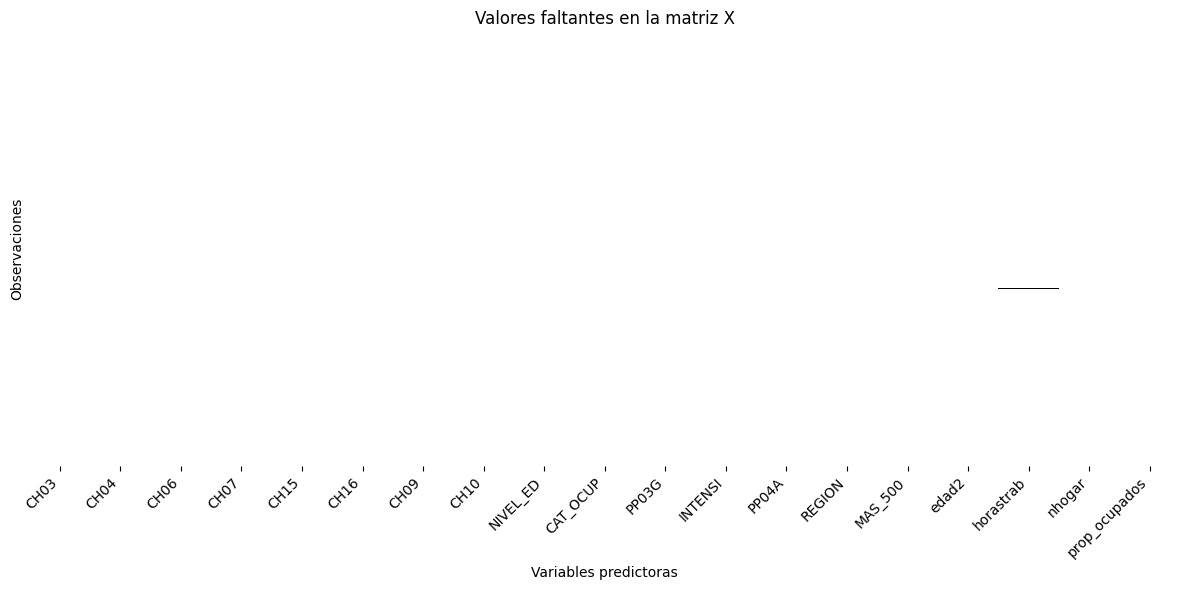

Observaciones originales: 19560
Observaciones completas: 19511
Observaciones eliminadas: 49
Variables antes de dummies: 19
Columnas después de dummies: 51
DIFERENCIA DE MEDIAS


,Variable,Formal,Informal,Diferencia,t_stat,p_valor,Significancia
0,CH06,43.4791,39.4016,-4.0775,-21.3956,0.0000,***
1,edad2,2033.6093,1754.0696,-279.5397,-16.6095,0.0000,***
2,horastrab,36.5339,33.3518,-3.1822,-11.7360,0.0000,***
3,nhogar,3.2992,3.8770,0.5777,22.0586,0.0000,***
4,prop_ocupados,0.6483,0.6270,-0.0214,-5.6862,0.0000,***
5,CH03_2,0.2456,0.2001,-0.0455,-7.6338,0.0000,***
6,CH03_3,0.1601,0.2961,0.1360,22.5735,0.0000,***
7,CH03_4,0.0122,0.0220,0.0098,5.1879,0.0000,***
8,CH03_5,0.0071,0.0202,0.0131,7.6843,0.0000,***
9,CH03_6,0.0046,0.0055,0.0009,0.8920,0.3724,


In [34]:

# ============================================================
# PARTE I - CONSIGNA 3
# VALORES FALTANTES Y DIFERENCIAS DE MEDIAS
# ============================================================

from scipy.stats import ttest_ind

# ============================================================
# 3.1. PREPARACIÓN DE LA MATRIZ X
# ============================================================

# Corregir la edad no informada
datos_indiv["CH06"] = datos_indiv["CH06"].replace(99, np.nan)
datos_indiv["edad2"] = datos_indiv["CH06"] ** 2

# Corregir códigos inválidos de horas
variables_horas = ["PP3E_TOT", "PP3F_TOT"]

datos_indiv[variables_horas] = (
    datos_indiv[variables_horas].replace(999, np.nan)
)

datos_indiv["horastrab"] = (
    datos_indiv["PP3E_TOT"] + datos_indiv["PP3F_TOT"]
)

# Matriz de predictores originales y construidos
X = datos_indiv[variables_x].copy()
y = datos_indiv["informal"].copy()


# ============================================================
# 3.2. TABLA DE VALORES FALTANTES
# ============================================================

tabla_faltantes = pd.DataFrame({
    "N_faltantes": X.isna().sum(),
    "Porcentaje": (X.isna().mean() * 100).round(3)
})

tabla_faltantes = tabla_faltantes.sort_values(
    "N_faltantes",
    ascending=False
)

print("VALORES FALTANTES")
display(tabla_faltantes)

print("Observaciones originales:", len(X))
print("Casos con algún faltante:", X.isna().any(axis=1).sum())


# ============================================================
# 3.3. HEATMAP DE VALORES FALTANTES
# ============================================================

plt.figure(figsize=(12, 6))

sns.heatmap(
    X.isna(),
    cmap="Greys",
    cbar=False,
    yticklabels=False
)

plt.title("Valores faltantes en la matriz X")
plt.xlabel("Variables predictoras")
plt.ylabel("Observaciones")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    join(b_path_figr, "heatmap_faltantes.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3.4. TRATAMIENTO DE VALORES FALTANTES
# ============================================================

# Conservar solamente casos completos
datos_completos = datos_indiv.dropna(
    subset=variables_x
).copy()

print("Observaciones originales:", len(datos_indiv))
print("Observaciones completas:", len(datos_completos))
print("Observaciones eliminadas:",
      len(datos_indiv) - len(datos_completos))


# ============================================================
# 3.5. TRANSFORMACIÓN DE VARIABLES CATEGÓRICAS
# ============================================================

# Variables numéricas continuas o de conteo
variables_numericas = [
    "CH06",
    "edad2",
    "horastrab",
    "nhogar",
    "prop_ocupados"
]

# El resto son variables categóricas
variables_categoricas = [
    var for var in variables_x
    if var not in variables_numericas
]

# Convertir categóricas a dummies
X_dummies = pd.get_dummies(
    datos_completos[variables_x],
    columns=variables_categoricas,
    drop_first=True,
    dtype=int
)

# Variable dependiente correspondiente
y_completo = datos_completos["informal"]

print("Variables antes de dummies:", len(variables_x))
print("Columnas después de dummies:", X_dummies.shape[1])


# ============================================================
# 3.6. DIFERENCIA DE MEDIAS ENTRE FORMALES E INFORMALES
# ============================================================

resultados = []

for var in X_dummies.columns:

    formales = X_dummies.loc[
        y_completo == 0, var
    ].astype(float)

    informales = X_dummies.loc[
        y_completo == 1, var
    ].astype(float)

    # Prueba t de Welch
    t_stat, p_valor = ttest_ind(
        informales,
        formales,
        equal_var=False
    )

    resultados.append({
        "Variable": var,
        "Formal": formales.mean(),
        "Informal": informales.mean(),
        "Diferencia": informales.mean() - formales.mean(),
        "t_stat": t_stat,
        "p_valor": p_valor
    })

tabla_medias = pd.DataFrame(resultados)

# Indicadores de significancia
tabla_medias["Significancia"] = np.select(
    [
        tabla_medias["p_valor"] < 0.01,
        tabla_medias["p_valor"] < 0.05,
        tabla_medias["p_valor"] < 0.10
    ],
    ["***", "**", "*"],
    default=""
)

tabla_medias = tabla_medias.round(4)

print("DIFERENCIA DE MEDIAS")
display(tabla_medias)


# ============================================================
# 3.7. GUARDAR TABLAS
# ============================================================

tabla_faltantes.to_csv(
    join(b_path_tabl, "tabla_faltantes.csv"),
    encoding="utf-8-sig"
)

tabla_medias.to_csv(
    join(b_path_tabl, "tabla_diferencia_medias.csv"),
    index=False,
    encoding="utf-8-sig"
)


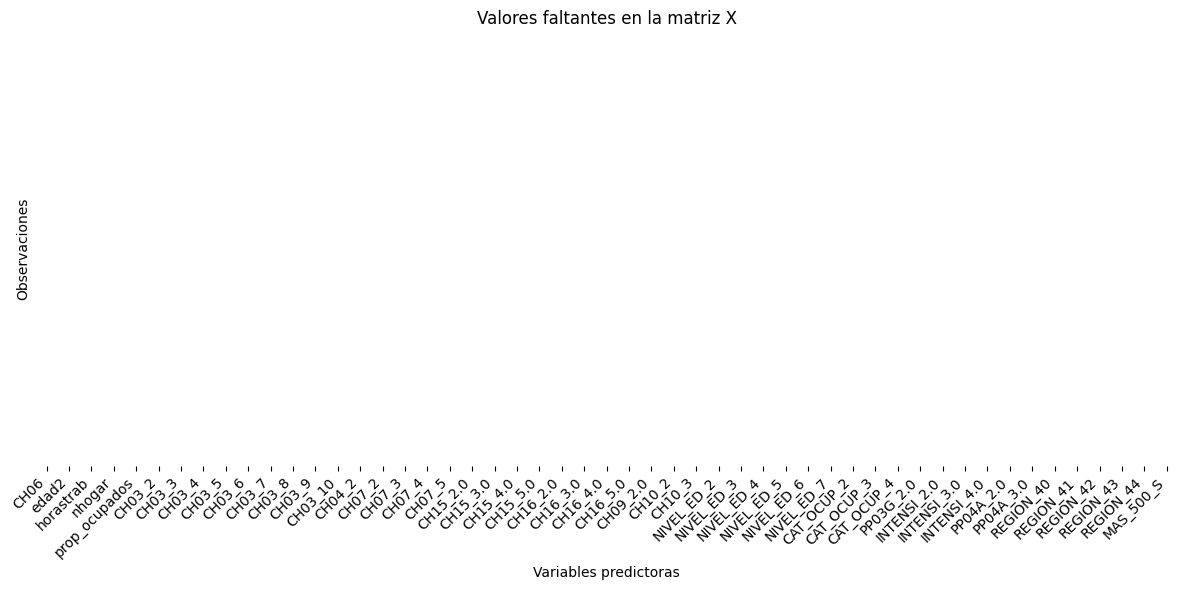

In [38]:
# ============================================================
# HEATMAP COMPLETO DE FALTANTES
# ============================================================

plt.figure(figsize=(12, 6))

sns.heatmap(
    X.isna(),
    cmap="binary",
    cbar=False,
    yticklabels=False
)

plt.title("Valores faltantes en la matriz X")
plt.xlabel("Variables predictoras")
plt.ylabel("Observaciones")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    join(b_path_figr, "heatmap_faltantes_completo.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [37]:

# ============================================================
# PARTE I - CONSIGNA 4
# DIVISIÓN DE ENTRENAMIENTO Y PRUEBA
# ============================================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

# ============================================================
# 4.1. DEFINIR MATRIZ X Y VECTOR y
# ============================================================

# Variables numéricas
variables_numericas = [
    "CH06",
    "edad2",
    "horastrab",
    "nhogar",
    "prop_ocupados"
]

# Variables categóricas
variables_categoricas = [
    var for var in variables_x
    if var not in variables_numericas
]

# Matriz de predictores con variables categóricas codificadas
X = pd.get_dummies(
    datos_completos[variables_x],
    columns=variables_categoricas,
    drop_first=True,
    dtype=int
)

# Variable dependiente
y = datos_completos["informal"].copy()


# ============================================================
# 4.2. DIVIDIR EN TRAIN Y TEST
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.70,
    random_state=444
)


# ============================================================
# 4.3. AGREGAR INTERCEPTO
# ============================================================

X_train.insert(0, "const", 1)
X_test.insert(0, "const", 1)


# ============================================================
# 4.4. VERIFICAR LAS DIMENSIONES
# ============================================================

print("Dimensiones de entrenamiento:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nDimensiones de prueba:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nDistribución de informalidad:")
print("Train:")
print(y_train.value_counts(normalize=True).round(4))

print("\nTest:")
print(y_test.value_counts(normalize=True).round(4))


# ============================================================
# 4.5. GUARDAR LA BASE LIMPIA
# ============================================================

datos_completos.to_csv(
    join(b_path_data, "EPH_T126_limpia.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("\nBase limpia guardada correctamente.")


Dimensiones de entrenamiento:
X_train: (13657, 52)
y_train: (13657,)

Dimensiones de prueba:
X_test: (5854, 52)
y_test: (5854,)

Distribución de informalidad:
Train:
informal
0    0.5503
1    0.4497
Name: proportion, dtype: float64

Test:
informal
0    0.5511
1    0.4489
Name: proportion, dtype: float64

Base limpia guardada correctamente.
